# Pivot index and Vendi score: does specialization predict acceptance?

**Question.** When a PI submits a paper that departs from their own earlier work, is it less likely to be accepted?

**Team decisions used here**
1. Only papers from 2021 on. Earlier papers have no OpenReview ids, so namesakes get merged (one name such as "Yang Liu" maps to 31 profiles in 2021+). Every author, the PI included, is identified by their OpenReview id.
2. A resubmitted paper is kept once: the accepted version if there is one, otherwise the latest. As a check we also drop every paper in a chain.
3. The PI is the last author. A PI needs at least 5 papers in earlier years for their paper to enter the analysis.
4. Withdrawn and desk-rejected papers have no decision, so they are left out of the acceptance models. They do have reviewer scores, so they stay in the score models.

**Plan:** the simplest model first, then one change at a time. The measures are computed in `scripts/specialization.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyfixest as pf
from scipy import sparse
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from statsmodels.discrete.conditional_models import ConditionalLogit

from scripts import specialization as sp

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Colours: first three categorical slots of a colour-blind-checked palette
BLUE, ORANGE, AQUA = "#257de0", "#f47230", "#00b894"
TEXT, MUTED, GRID = "#191919", "#666666", "#e5e5e5"

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "font.size": 10,
    "text.color": TEXT,
    "axes.labelcolor": TEXT,
    "axes.edgecolor": MUTED,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "lines.linewidth": 2,
})

## 1. Data

In [2]:
papers, embeddings = sp.load_master("../embeddings/master.parquet", min_year=2021)

print(f"Papers from 2021 on: {len(papers):,}")
papers["decision_group"].value_counts()

Papers from 2021 on: 30,433


decision_group
reject           13917
accept            9490
withdrawn         6860
desk_rejected      166
Name: count, dtype: int64

## 2. Resubmissions

Two papers are versions of the same submission when they share an author id, come from different years and have a cosine similarity of at least 0.90.

In [3]:
chain = sp.find_resubmission_chains(papers, embeddings, similarity_threshold=0.90)
n_chains = (chain.value_counts() > 1).sum()

drop_team_rule = sp.resubmissions_to_drop(papers, chain, rule="accepted_or_latest")
drop_all_chains = sp.resubmissions_to_drop(papers, chain, rule="drop_all")

print(f"Chains of resubmissions: {n_chains}")
print(f"Papers left out with the team rule: {len(drop_team_rule)}")
print(f"Papers left out when dropping whole chains: {len(drop_all_chains)}")

Chains of resubmissions: 433
Papers left out with the team rule: 449
Papers left out when dropping whole chains: 882


## 3. Measures

For a paper $j$ by PI $a$ in year $t$, the history $H(a,t)$ holds all of $a$'s papers (any author position) from years before $t$. With unit-length embeddings $e$:

| Measure | Definition | Reads as |
|---|---|---|
| `pivot` | $1 - \cos(e_j, \bar e_{H})$ | distance from the PI's average past paper (main measure) |
| `pivot_nn` | $1 - \max_{i \in H} \cos(e_j, e_i)$ | distance from the closest past paper |
| `pivot_recent` | same as `pivot`, past papers weighted by $2^{-\text{age}/2}$ | distance from the PI's *recent* agenda |
| `vendi` | Vendi score of 5 past papers, averaged over 20 random draws | number of distinct directions in the PI's past work (1 to 5) |

The Vendi score is the exponential of the entropy of the eigenvalues of the $5 \times 5$ cosine-similarity matrix divided by 5. Fixing the number of papers at 5 keeps PIs with long and short histories comparable.

In [4]:
measures_team_rule = sp.compute_pi_measures(sp.build_author_papers(papers, drop_team_rule), embeddings)
measures_all_chains = sp.compute_pi_measures(sp.build_author_papers(papers, drop_all_chains), embeddings)

# pi_id is an OpenReview id (sometimes an e-mail address), so we do not print it
measures_team_rule.drop(columns="pi_id").describe().round(3)

,paper_idx,year,n_prior,career_years,pivot,pivot_nn,pivot_recent,vendi
count,29984.000,29984.000,29984.000,29984.000,18205.000,18205.000,18205.000,8713.000
mean,20935.373,2023.712,4.662,1.446,0.447,0.443,0.446,3.538
std,8800.444,1.339,8.708,1.441,0.141,0.151,0.142,0.341
min,5637.000,2021.000,0.000,0.000,0.093,0.100,0.088,1.887
25%,13306.750,2023.000,0.000,0.000,0.343,0.333,0.341,3.329
50%,21001.500,2024.000,1.000,1.000,0.435,0.438,0.433,3.577
75%,28570.250,2025.000,6.000,3.000,0.542,0.549,0.543,3.770
max,36069.000,2025.000,89.000,4.000,1.019,1.015,1.019,4.385


## 4. Analysis sample

We keep PI papers with at least 5 prior papers. Each measure is standardised on the decided papers, so every coefficient reads as **the change in the outcome for a one-standard-deviation increase in the measure**.

In [5]:
MEASURES = ["pivot", "pivot_nn", "pivot_recent", "vendi"]
MIN_PRIOR = 5


def make_sample(measures: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    # Returns (scored, decided): papers with a reviewer score, and accepted/rejected papers
    outcomes = papers[["decision_group", "accepted", "mean_score", "n_authors"]]
    sample = measures.merge(outcomes, left_on="paper_idx", right_index=True)
    sample = sample[sample["n_prior"] >= MIN_PRIOR].copy()

    sample["accepted"] = sample["accepted"].astype(int)
    sample["log_n_prior"] = np.log(sample["n_prior"])
    sample["pi_year"] = sample["pi_id"] + "_" + sample["year"].astype(str)

    decided = sample[sample["decision_group"].isin(["accept", "reject"])].copy()

    for column in MEASURES:
        mean, std = decided[column].mean(), decided[column].std()
        decided[column + "_z"] = (decided[column] - mean) / std
        sample[column + "_z"] = (sample[column] - mean) / std

    scored = sample.dropna(subset=["mean_score"]).copy()
    return scored, decided


scored, decided = make_sample(measures_team_rule)
scored_all_chains, decided_all_chains = make_sample(measures_all_chains)

print(f"Decided papers: {len(decided):,} from {decided['pi_id'].nunique():,} PIs, acceptance rate {decided['accepted'].mean():.1%}")
print(f"Scored papers (withdrawn included): {len(scored):,}")
decided.groupby("year").size().rename("decided papers")

Decided papers: 6,920 from 1,553 PIs, acceptance rate 48.8%
Scored papers (withdrawn included): 8,651


year
2022     377
2023     940
2024    1974
2025    3629
Name: decided papers, dtype: int64

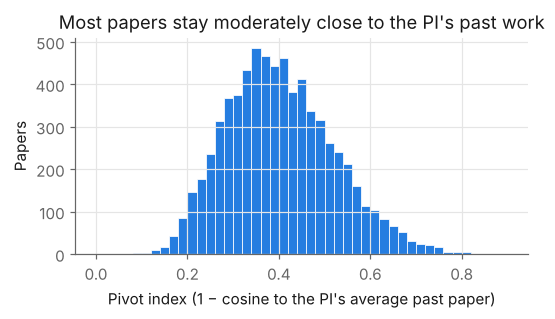

,pivot,pivot_nn,pivot_recent,vendi
count,6920.000,6920.000,6920.000,6920.000
mean,0.403,0.390,0.401,3.533
std,0.118,0.126,0.118,0.341
min,0.093,0.100,0.088,1.887
25%,0.318,0.298,0.315,3.324
50%,0.393,0.383,0.390,3.572
75%,0.480,0.477,0.478,3.766
max,0.866,0.824,0.877,4.385


In [6]:
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(decided["pivot"], bins=np.linspace(0, 0.9, 46), color=BLUE, edgecolor="white", linewidth=0.5)
ax.set(xlabel="Pivot index (1 − cosine to the PI's average past paper)", ylabel="Papers",
       title="Most papers stay moderately close to the PI's past work")
plt.tight_layout()
plt.show()

decided[MEASURES].describe().round(3)

## 5. From the simplest model up

All models are linear probability models: the outcome is accepted (1) or rejected (0), so a coefficient is a change in acceptance probability. Standard errors are clustered by PI, because papers by the same PI are not independent.

| Model | Formula | What changes |
|---|---|---|
| M0 | `accepted ~ pivot + year` | compares papers across all PIs |
| M1 | `accepted ~ pivot + PI + year` | compares each PI's papers with their other papers |
| M2 | M1 + `log(n_prior)` + `n_authors` | adds history length and team size |
| M3 | `accepted ~ pivot + n_authors + PI×year` | compares papers by the same PI **in the same year** |

M3 answers the concern about prolific PIs: papers that share a PI and a year share the same history, so only the pivot differs between them. PIs with a single paper in a year drop out of M3.

In [7]:
CLUSTER_BY_PI = {"CRV1": "pi_id"}

ladder = {
    "M0 pooled": pf.feols("accepted ~ pivot_z | year", decided, vcov=CLUSTER_BY_PI),
    "M1 PI FE": pf.feols("accepted ~ pivot_z | pi_id + year", decided, vcov=CLUSTER_BY_PI),
    "M2 PI FE + controls": pf.feols("accepted ~ pivot_z + log_n_prior + n_authors | pi_id + year", decided, vcov=CLUSTER_BY_PI),
    "M3 PI×year FE": pf.feols("accepted ~ pivot_z + n_authors | pi_year", decided, vcov=CLUSTER_BY_PI),
}


def coefficient_table(fits: dict, variable: str) -> pd.DataFrame:
    # One row per model: the coefficient of `variable`, its 95% CI and p-value
    rows = []
    for name, fit in fits.items():
        estimate = fit.tidy().loc[variable]
        rows.append({
            "model": name,
            "coefficient": estimate["Estimate"],
            "ci_low": estimate["2.5%"],
            "ci_high": estimate["97.5%"],
            "p_value": estimate["Pr(>|t|)"],
            "n_papers": fit._N,
        })
    return pd.DataFrame(rows).set_index("model")


ladder_table = coefficient_table(ladder, "pivot_z")
ladder_table.round(4)

/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 475 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 475 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 998 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")


,coefficient,ci_low,ci_high,p_value,n_papers
model,,,,,
M0 pooled,-0.0215,-0.0345,-0.0086,0.0012,6920
M1 PI FE,-0.0119,-0.0279,0.0040,0.1418,6445
M2 PI FE + controls,-0.0118,-0.0279,0.0043,0.1499,6445
M3 PI×year FE,-0.0100,-0.0270,0.0070,0.2479,5922


Papers whose PI has only one decided paper (or one per year, in M3) carry no within-PI information. That is why N shrinks from M0 to M3.

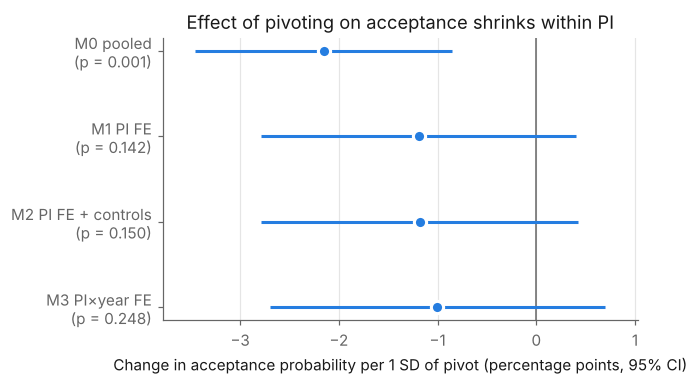

In [8]:
def plot_coefficients(table: pd.DataFrame, title: str, xlabel: str, filename: str, scale: float = 100):
    fig, ax = plt.subplots(figsize=(6, 0.6 * len(table) + 1.2))
    positions = np.arange(len(table))[::-1]

    ax.axvline(0, color=MUTED, linewidth=1)
    ax.hlines(positions, table["ci_low"] * scale, table["ci_high"] * scale, color=BLUE, linewidth=2)
    ax.plot(table["coefficient"] * scale, positions, "o", color=BLUE, markersize=8,
            markeredgecolor="white", markeredgewidth=2)

    # the p-value goes into the row label, so it never overlaps the intervals
    row_labels = [f"{name}\n(p = {p_value:.3f})" for name, p_value in zip(table.index, table["p_value"])]
    left = min(table["ci_low"].min() * scale, 0)
    right = max(table["ci_high"].max() * scale, 0)
    ax.set_xlim(left - 0.08 * (right - left), right + 0.08 * (right - left))

    ax.set_yticks(positions, row_labels)
    ax.set(xlabel=xlabel, title=title)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    fig.savefig(FIG_DIR / filename, bbox_inches="tight")
    plt.show()


plot_coefficients(
    ladder_table,
    title="Effect of pivoting on acceptance shrinks within PI",
    xlabel="Change in acceptance probability per 1 SD of pivot (percentage points, 95% CI)",
    filename="pivot_model_ladder.png",
)

## 6. Why the effect shrinks: between PIs versus within PI

Left: papers grouped by their raw pivot. Right: each paper's pivot and outcome minus its PI's own average, so a PI is only compared with themselves. The pooled gap is mostly a difference **between** PIs (PIs who pivot a lot are accepted less), not a penalty a PI pays when they pivot.

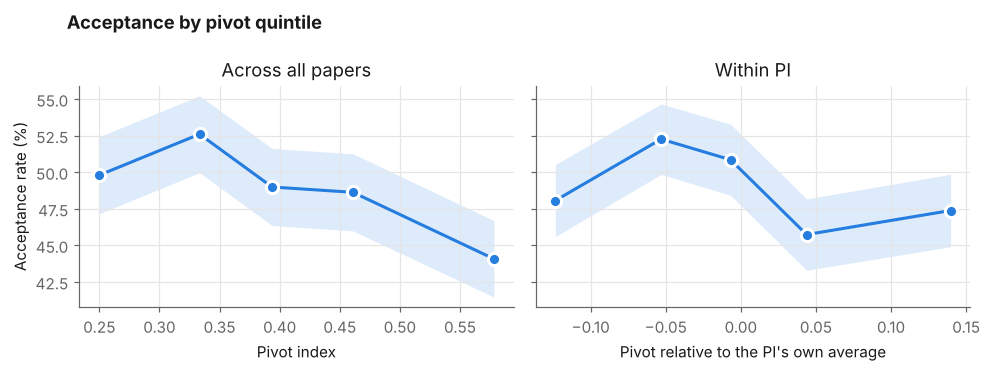

x   mean     se    low   high
              pivot                                   
across papers Q1     0.249  0.498  0.013  0.471  0.524
              Q2     0.333  0.526  0.013  0.500  0.552
              Q3     0.394  0.490  0.013  0.464  0.516
              Q4     0.461  0.486  0.013  0.460  0.513
              Q5     0.578  0.441  0.013  0.415  0.467
within PI     Q1    -0.123  0.481  0.013  0.456  0.505
              Q2    -0.053  0.523  0.012  0.499  0.547
              Q3    -0.007  0.509  0.012  0.484  0.533
              Q4     0.044  0.457  0.012  0.433  0.482
              Q5     0.140  0.474  0.013  0.449  0.499

In [9]:
QUINTILES = ["Q1", "Q2", "Q3", "Q4", "Q5"]


def binned_rate(values: pd.Series, outcome: pd.Series) -> pd.DataFrame:
    # Mean outcome per quintile of `values`, with a 95% interval for the mean
    bins = pd.qcut(values, q=5, labels=QUINTILES)
    grouped = outcome.groupby(bins, observed=True)
    table = pd.DataFrame({"x": values.groupby(bins, observed=True).mean(), "mean": grouped.mean(), "se": grouped.sem()})
    table["low"] = table["mean"] - 1.96 * table["se"]
    table["high"] = table["mean"] + 1.96 * table["se"]
    return table


# Within PI: PIs with at least two decided papers, each paper relative to its PI's average
repeat_pis = decided[decided.groupby("pi_id")["pi_id"].transform("size") > 1].copy()
repeat_pis["pivot_within"] = repeat_pis["pivot"] - repeat_pis.groupby("pi_id")["pivot"].transform("mean")
repeat_pis["accepted_within"] = (
    repeat_pis["accepted"] - repeat_pis.groupby("pi_id")["accepted"].transform("mean") + repeat_pis["accepted"].mean()
)

between = binned_rate(decided["pivot"], decided["accepted"])
within = binned_rate(repeat_pis["pivot_within"], repeat_pis["accepted_within"])

fig, axs = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
panels = [
    (axs[0], between, "Pivot index", "Across all papers"),
    (axs[1], within, "Pivot relative to the PI's own average", "Within PI"),
]
for ax, table, xlabel, title in panels:
    ax.fill_between(table["x"], table["low"] * 100, table["high"] * 100, color=BLUE, alpha=0.15, linewidth=0)
    ax.plot(table["x"], table["mean"] * 100, "-o", color=BLUE, markersize=8, markeredgecolor="white", markeredgewidth=2)
    ax.set(xlabel=xlabel, title=title)
axs[0].set_ylabel("Acceptance rate (%)")
fig.suptitle("Acceptance by pivot quintile", x=0.06, ha="left", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "pivot_between_within.png", bbox_inches="tight")
plt.show()

pd.concat({"across papers": between, "within PI": within}).round(3)

## 7. Robustness of M2

Each row changes one thing in M2:
- **Drop whole chains:** leave out every resubmitted paper, so the choice of version never depends on the decision.
- **Other pivots:** nearest past paper, or recency-weighted history.
- **Pivot quintiles:** dummies in place of a straight line, in case the effect is not linear.
- **Fixed-effects logit:** a conditional logit with PI groups, in place of the linear probability model.

In [10]:
M2_CONTROLS = "log_n_prior + n_authors | pi_id + year"

robustness = {
    "M2 (team rule)": ladder["M2 PI FE + controls"],
    "M2, drop whole chains": pf.feols(f"accepted ~ pivot_z + {M2_CONTROLS}", decided_all_chains, vcov=CLUSTER_BY_PI),
}
robustness_table = coefficient_table(robustness, "pivot_z")

for column, label in [("pivot_nn_z", "M2, nearest past paper"), ("pivot_recent_z", "M2, recency-weighted (2y half-life)")]:
    fit = pf.feols(f"accepted ~ {column} + {M2_CONTROLS}", decided, vcov=CLUSTER_BY_PI)
    robustness_table.loc[label] = coefficient_table({label: fit}, column).iloc[0]

robustness_table.round(4)

/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 467 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 475 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 475 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")


,coefficient,ci_low,ci_high,p_value,n_papers
model,,,,,
M2 (team rule),-0.0118,-0.0279,0.0043,0.1499,6445.0
"M2, drop whole chains",-0.0141,-0.0303,0.0022,0.0899,6255.0
"M2, nearest past paper",-0.0085,-0.0240,0.0070,0.2821,6445.0
"M2, recency-weighted (2y half-life)",-0.0113,-0.0274,0.0048,0.1680,6445.0


In [11]:
decided["pivot_quintile"] = pd.qcut(decided["pivot"], q=5, labels=QUINTILES)
quintile_fit = pf.feols(f"accepted ~ i(pivot_quintile, ref='Q1') + {M2_CONTROLS}", decided, vcov=CLUSTER_BY_PI)
quintile_fit.tidy()[["Estimate", "2.5%", "97.5%", "Pr(>|t|)"]].round(4)

/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 475 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")


,Estimate,2.5%,97.5%,Pr(>|t|)
Coefficient,,,,
pivot_quintile::Q2,0.0232,-0.0203,0.0667,0.2957
pivot_quintile::Q3,-0.0062,-0.0514,0.0390,0.7877
pivot_quintile::Q4,-0.0133,-0.0613,0.0347,0.5866
pivot_quintile::Q5,-0.0304,-0.0793,0.0185,0.2229
log_n_prior,0.0110,-0.0924,0.1144,0.8344
n_authors,0.0174,0.0110,0.0238,0.0000


In [12]:
# Conditional (fixed-effects) logit: PI effects are conditioned out, year enters as dummies
year_dummies = pd.get_dummies(decided["year"], prefix="year", drop_first=True).astype(float)
logit_X = pd.concat([decided[["pivot_z", "log_n_prior", "n_authors"]], year_dummies], axis=1)

logit_fit = ConditionalLogit(decided["accepted"].to_numpy(), logit_X.to_numpy(), groups=decided["pi_id"].to_numpy()).fit(disp=0)
pivot_position = list(logit_X.columns).index("pivot_z")

print(f"Odds ratio per 1 SD of pivot: {np.exp(logit_fit.params[pivot_position]):.3f}")
print(f"p-value: {logit_fit.pvalues[pivot_position]:.3f}")

/usr/local/lib/python3.13/site-packages/statsmodels/discrete/conditional_models.py:303: ModelWarning: Dropped 714 groups and 1121 observations for having no within-group variance
  super().__init__(endog, exog, missing=missing, **kwargs)


Odds ratio per 1 SD of pivot: 0.953
p-value: 0.127


## 8. Reviewer score as the outcome

A binary decision throws away information. The mean reviewer score is finer and also exists for most withdrawn papers. Withdrawals often follow bad reviews, so dropping them hides some of the papers the effect is about.

In [13]:
score_fits = {
    "Score, pooled": pf.feols("mean_score ~ pivot_z | year", scored, vcov=CLUSTER_BY_PI),
    "Score, PI FE + controls": pf.feols(f"mean_score ~ pivot_z + {M2_CONTROLS}", scored, vcov=CLUSTER_BY_PI),
    "Score, PI×year FE": pf.feols("mean_score ~ pivot_z + n_authors | pi_year", scored, vcov=CLUSTER_BY_PI),
}
score_table = coefficient_table(score_fits, "pivot_z")
print(f"Standard deviation of the mean score: {scored['mean_score'].std():.2f} points")
score_table.round(4)

Standard deviation of the mean score: 1.21 points


/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 454 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 974 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")


,coefficient,ci_low,ci_high,p_value,n_papers
model,,,,,
"Score, pooled",-0.0841,-0.1115,-0.0566,0.0000,8651
"Score, PI FE + controls",-0.0486,-0.0812,-0.0159,0.0036,8197
"Score, PI×year FE",-0.0456,-0.0806,-0.0106,0.0107,7677


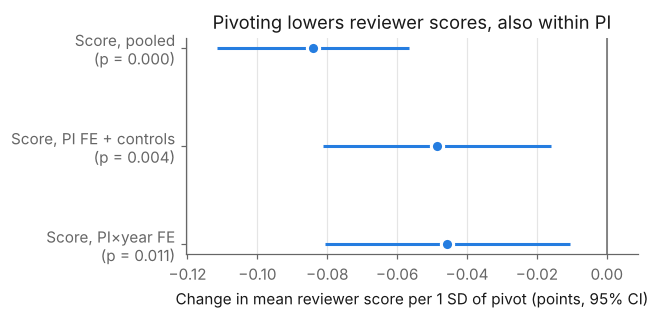

In [14]:
plot_coefficients(
    score_table,
    title="Pivoting lowers reviewer scores, also within PI",
    xlabel="Change in mean reviewer score per 1 SD of pivot (points, 95% CI)",
    filename="pivot_score_models.png",
    scale=1,
)

## 9. Vendi score: breadth of the PI's past work

First the patterns, then the models.
- How much does breadth vary *within* a PI, compared to *between* PIs? A within-PI model can only use the within part.
- Does a PI's breadth change over their career?
- Do broad PIs (foxes) pivot more?

In [15]:
def variance_split(data: pd.DataFrame, column: str) -> dict:
    within = data[column] - data.groupby("pi_id")[column].transform("mean")
    return {"measure": column, "total SD": data[column].std(), "within-PI SD": within.std(),
            "within share of variance": within.var() / data[column].var()}


pd.DataFrame([variance_split(decided, column) for column in ["pivot", "vendi"]]).set_index("measure").round(3)

,total SD,within-PI SD,within share of variance
measure,,,
pivot,0.118,0.091,0.602
vendi,0.341,0.106,0.096


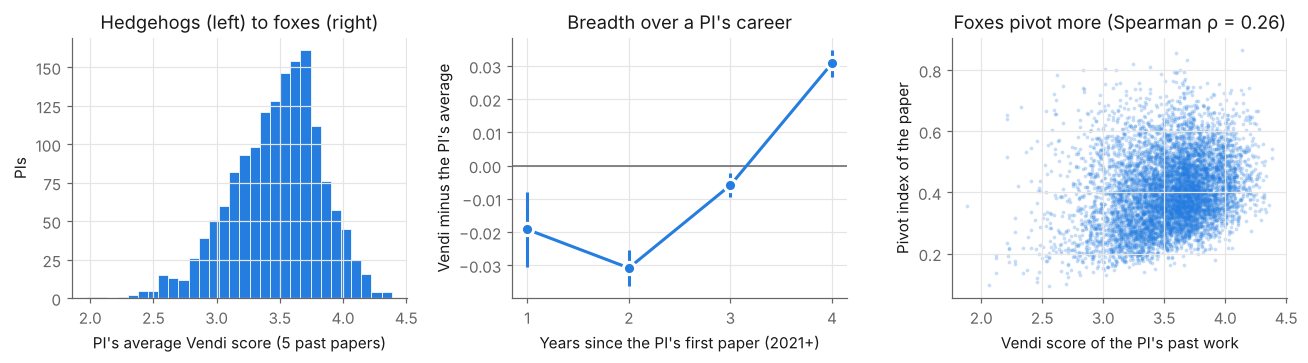

,mean,sem,size
career_years,,,
1,-0.019,0.006,523
2,-0.031,0.003,1589
3,-0.006,0.002,2430
4,0.031,0.002,2378


In [16]:
# One value per PI: their average breadth across their papers
pi_breadth = decided.groupby("pi_id").agg(vendi=("vendi", "mean"), pivot=("pivot", "mean"),
                                          acceptance=("accepted", "mean"), n_papers=("paper_idx", "size"))

# Within PI: breadth relative to the PI's own average, by years since their first paper
decided["vendi_within"] = decided["vendi"] - decided.groupby("pi_id")["vendi"].transform("mean")
by_career = decided.groupby("career_years")["vendi_within"].agg(["mean", "sem", "size"])
by_career = by_career[by_career["size"] >= 50]

fig, axs = plt.subplots(1, 3, figsize=(12, 3.4))

axs[0].hist(pi_breadth["vendi"], bins=30, color=BLUE, edgecolor="white", linewidth=0.5)
axs[0].set(xlabel="PI's average Vendi score (5 past papers)", ylabel="PIs",
           title="Hedgehogs (left) to foxes (right)")

axs[1].errorbar(by_career.index, by_career["mean"], yerr=1.96 * by_career["sem"], color=BLUE,
                marker="o", markersize=8, markeredgecolor="white", markeredgewidth=2, capsize=0)
axs[1].axhline(0, color=MUTED, linewidth=1)
axs[1].set_xticks(by_career.index)
axs[1].set(xlabel="Years since the PI's first paper (2021+)", ylabel="Vendi minus the PI's average",
           title="Breadth over a PI's career")

axs[2].scatter(decided["vendi"], decided["pivot"], s=6, color=BLUE, alpha=0.25, linewidth=0)
axs[2].set(xlabel="Vendi score of the PI's past work", ylabel="Pivot index of the paper",
           title=f"Foxes pivot more (Spearman ρ = {decided[['vendi', 'pivot']].corr('spearman').iloc[0, 1]:.2f})")

plt.tight_layout()
fig.savefig(FIG_DIR / "vendi_patterns.png", bbox_inches="tight")
plt.show()

by_career.round(3)

**Reading the career panel.** Within a PI, breadth rises with career length. Part of this is mechanical: the 5 papers are drawn from a history that grows and gets older each year, so the pool itself becomes more spread. Breadth computed on a fixed window (for example the last 2 years only) would separate real broadening from this growth.

Models with Vendi, all with PI and year fixed effects and the M2 controls:
- **V1:** Vendi alone.
- **V2:** pivot and Vendi together.
- **V3:** V2 plus their interaction. Is pivoting costlier for hedgehogs (low Vendi) than for foxes?

In [17]:
vendi_fits = {
    "V1 Vendi alone": pf.feols(f"accepted ~ vendi_z + {M2_CONTROLS}", decided, vcov=CLUSTER_BY_PI),
    "V2 pivot + Vendi": pf.feols(f"accepted ~ pivot_z + vendi_z + {M2_CONTROLS}", decided, vcov=CLUSTER_BY_PI),
    "V3 pivot × Vendi": pf.feols(f"accepted ~ pivot_z * vendi_z + {M2_CONTROLS}", decided, vcov=CLUSTER_BY_PI),
}

vendi_rows = []
for name, fit in vendi_fits.items():
    estimates = fit.tidy()
    for variable in ["pivot_z", "vendi_z", "pivot_z:vendi_z"]:
        if variable in estimates.index:
            vendi_rows.append({"model": name, "term": variable, "coefficient": estimates.loc[variable, "Estimate"],
                               "ci_low": estimates.loc[variable, "2.5%"], "ci_high": estimates.loc[variable, "97.5%"],
                               "p_value": estimates.loc[variable, "Pr(>|t|)"]})

pd.DataFrame(vendi_rows).set_index(["model", "term"]).round(4)

/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 475 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 475 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")
/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 475 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")


coefficient  ci_low  ci_high  p_value
model            term                                                  
V1 Vendi alone   vendi_z               0.0251 -0.0155   0.0658   0.2250
V2 pivot + Vendi pivot_z              -0.0112 -0.0272   0.0048   0.1705
                 vendi_z               0.0232 -0.0177   0.0640   0.2659
V3 pivot × Vendi pivot_z              -0.0120 -0.0280   0.0040   0.1414
                 vendi_z               0.0244 -0.0164   0.0652   0.2411
                 pivot_z:vendi_z      -0.0079 -0.0217   0.0058   0.2572

In [18]:
vendi_score_fit = pf.feols(f"mean_score ~ pivot_z * vendi_z + {M2_CONTROLS}", scored, vcov=CLUSTER_BY_PI)
vendi_score_fit.tidy()[["Estimate", "2.5%", "97.5%", "Pr(>|t|)"]].round(4)

/usr/local/lib/python3.13/site-packages/pyfixest/estimation/formula/model_matrix.py:346: UserWarning: 454 singleton fixed effect(s) dropped from the model.
  warnings.warn(f"{n_dropped} {reason} dropped from the model.")


,Estimate,2.5%,97.5%,Pr(>|t|)
Coefficient,,,,
pivot_z,-0.0490,-0.0815,-0.0165,0.0032
vendi_z,0.0544,-0.0332,0.1421,0.2233
log_n_prior,0.0438,-0.2089,0.2966,0.7339
n_authors,0.0492,0.0371,0.0614,0.0000
pivot_z:vendi_z,-0.0170,-0.0472,0.0133,0.2712


## 10. Out-of-sample check: predicting 2025 decisions

Train on 2022–2024 and test on 2025 papers by PIs seen in training. A logistic regression with one indicator per PI, shrunk towards zero (L2 penalty), plays the role of the PI effect. AUC is the chance that a random accepted paper gets a higher score than a random rejected one (0.5 = guessing).

In [19]:
train = decided[decided["year"] <= 2024]
test = decided[(decided["year"] == 2025) & decided["pi_id"].isin(train["pi_id"])]
train_pis = pd.Categorical(train["pi_id"]).categories


def design_matrix(data: pd.DataFrame, features: list[str], use_pi: bool) -> sparse.csr_matrix:
    blocks = []
    if use_pi:
        pi_codes = pd.Categorical(data["pi_id"], categories=train_pis).codes
        blocks.append(sparse.csr_matrix((np.ones(len(data)), (np.arange(len(data)), pi_codes)),
                                        shape=(len(data), len(train_pis))))
    if features:
        blocks.append(sparse.csr_matrix(data[features].to_numpy(dtype=float)))
    return sparse.hstack(blocks).tocsr()


feature_sets = {
    "pivot only": ([ "pivot_z"], False),
    "PI only": ([], True),
    "PI + pivot": (["pivot_z"], True),
    "PI + Vendi": (["vendi_z"], True),
    "PI + pivot + Vendi": (["pivot_z", "vendi_z"], True),
    "PI + pivot + Vendi + controls": (["pivot_z", "vendi_z", "log_n_prior", "n_authors"], True),
}

auc_rows = []
for name, (features, use_pi) in feature_sets.items():
    model = LogisticRegression(C=0.3, max_iter=3000)
    model.fit(design_matrix(train, features, use_pi), train["accepted"])
    predicted = model.predict_proba(design_matrix(test, features, use_pi))[:, 1]
    auc_rows.append({"features": name, "AUC": roc_auc_score(test["accepted"], predicted)})

auc_table = pd.DataFrame(auc_rows).set_index("features")
print(f"Train: {len(train):,} papers, test: {len(test):,} papers")
auc_table.round(4)

Train: 3,291 papers, test: 2,101 papers


,AUC
features,
pivot only,0.5109
PI only,0.5350
PI + pivot,0.5408
PI + Vendi,0.5340
PI + pivot + Vendi,0.5397
PI + pivot + Vendi + controls,0.5528


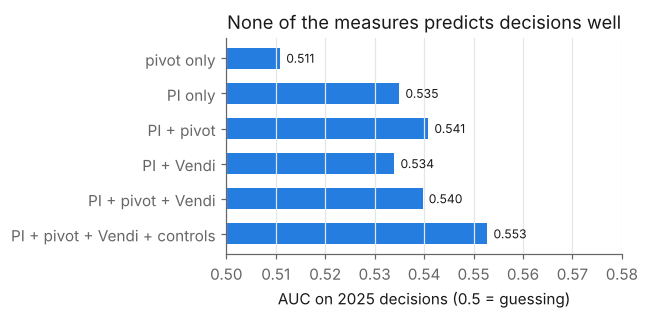

In [20]:
fig, ax = plt.subplots(figsize=(6, 3))
positions = np.arange(len(auc_table))[::-1]
ax.barh(positions, auc_table["AUC"] - 0.5, left=0.5, height=0.6, color=BLUE)
for position, auc in zip(positions, auc_table["AUC"]):
    ax.annotate(f"{auc:.3f}", (auc, position), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=TEXT)
ax.set_yticks(positions, auc_table.index)
ax.set(xlim=(0.5, 0.58), xlabel="AUC on 2025 decisions (0.5 = guessing)",
       title="None of the measures predicts decisions well")
ax.grid(axis="y", visible=False)
plt.tight_layout()
fig.savefig(FIG_DIR / "prediction_auc.png", bbox_inches="tight")
plt.show()

## 11. Summary

The numbers are in the tables above; the reading is:
1. **Across papers**, high-pivot papers are accepted less often (M0).
2. **Within PI**, the effect on acceptance is about half as large and not distinguishable from zero with this sample (M1–M3). Most of the pooled gap is a difference *between* PIs.
3. **Reviewer scores** do fall when a PI pivots, also within PI and within PI-year. The score is the more informative outcome.
4. **Vendi** varies mostly between PIs. Within PI it neither predicts acceptance nor changes how pivoting is received.
5. **Prediction** is weak for every feature set (AUC close to 0.5). These measures describe acceptance; they cannot forecast it.